/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


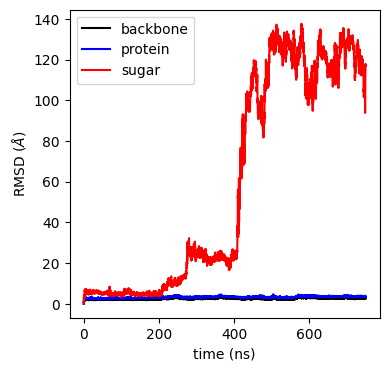

In [1]:


import MDAnalysis as mda
import numpy as np
#import pandas as pd
u=mda.Universe("protein_ligand.gro","final_production.xtc")
from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
def rmsd_for_atomgroups(universe, selection1, selection2=None):
    """Calulate the RMSD for selected atom groups.

    Parameters
    ----------
    universe: MDAnalysis.core.universe.Universe
        MDAnalysis universe.
    selection1: str
        Selection string for main atom group, also used during alignment.
    selection2: list of str, optional
        Selection strings for additional atom groups.

    Returns
    -------
    rmsd_df: pandas.core.frame.DataFrame
        DataFrame containing RMSD of the selected atom groups over time.
    """

    universe.trajectory[0]
    ref = universe
    rmsd_analysis = rms.RMSD(universe, ref, select=selection1, groupselections=selection2)
    rmsd_analysis.run()
    final_rmsd = rmsd_analysis.results.rmsd.T   # transpose makes it easier for plotting
    #time = final_rmsd[1]
    #columns = [selection1, *selection2] if selection2 else [selection1]
    #rmsd_df = pd.DataFrame(np.round(rmsd_analysis.rmsd[:, 2:], 2), columns=columns)
    #rmsd_df.index.name = "frame"
    return final_rmsd
final_rmsd = rmsd_for_atomgroups(u, "backbone", ["protein", "resname BMANA"])
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(4,4))
time=final_rmsd[1]
time=time/(1000)
ax = fig.add_subplot(111)
ax.plot(time, final_rmsd[2], 'k-',  label="backbone")
ax.plot(time, final_rmsd[3], 'b-', label="protein")
ax.plot(time, final_rmsd[4], 'r-', label="sugar")
ax.legend(loc="best")
ax.set_xlabel("time (ns)")
ax.set_ylabel(r"RMSD ($\AA$)")
fig.savefig("set1rmsd.jpg")
#rmsd.plot(title="RMSD of protein and ligand")
#plt.ylabel("RMSD (Å)")
#plt.savefig("set1rmsd.jpg")



/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


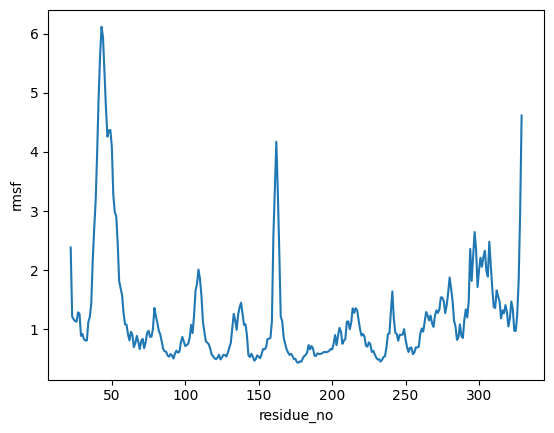

In [1]:
import MDAnalysis as mda
import numpy as np
#import pandas as pd
#import os
#current_working_directory=os.getcwd()
#print (current_working_directory)
#os.chdir('/home/kinjal/klauda_project/set2_tetraha')
#current_working_directory=os.getcwd()
#print (current_working_directory)
#u=mda.Universe("step4.1_equilibration.gro","final_production.xtc")
from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
import matplotlib.pyplot as plt
result_1=np.zeros((2,308))
u=mda.Universe("protein_ligand.gro","final_production.xtc")
u.trajectory[0]
average = align.AverageStructure(u, u, select='protein and name CA',
                                 ref_frame=0).run()
ref = average.results.universe
aligner = align.AlignTraj(u, ref,select='protein and name CA',in_memory=True).run()
c_alphas = u.select_atoms('protein and name CA')
R = rms.RMSF(c_alphas).run()
x_axis=c_alphas.resids
set1=R.results.rmsf
#current_working_directory=os.getcwd()
np.save("residue_no.npy",np.array(x_axis))
np.save("set1.npy",np.array(set1))
plt.plot(x_axis,set1)
plt.xlabel("residue_no")
plt.ylabel("rmsf")
plt.savefig("RMSF.jpg")

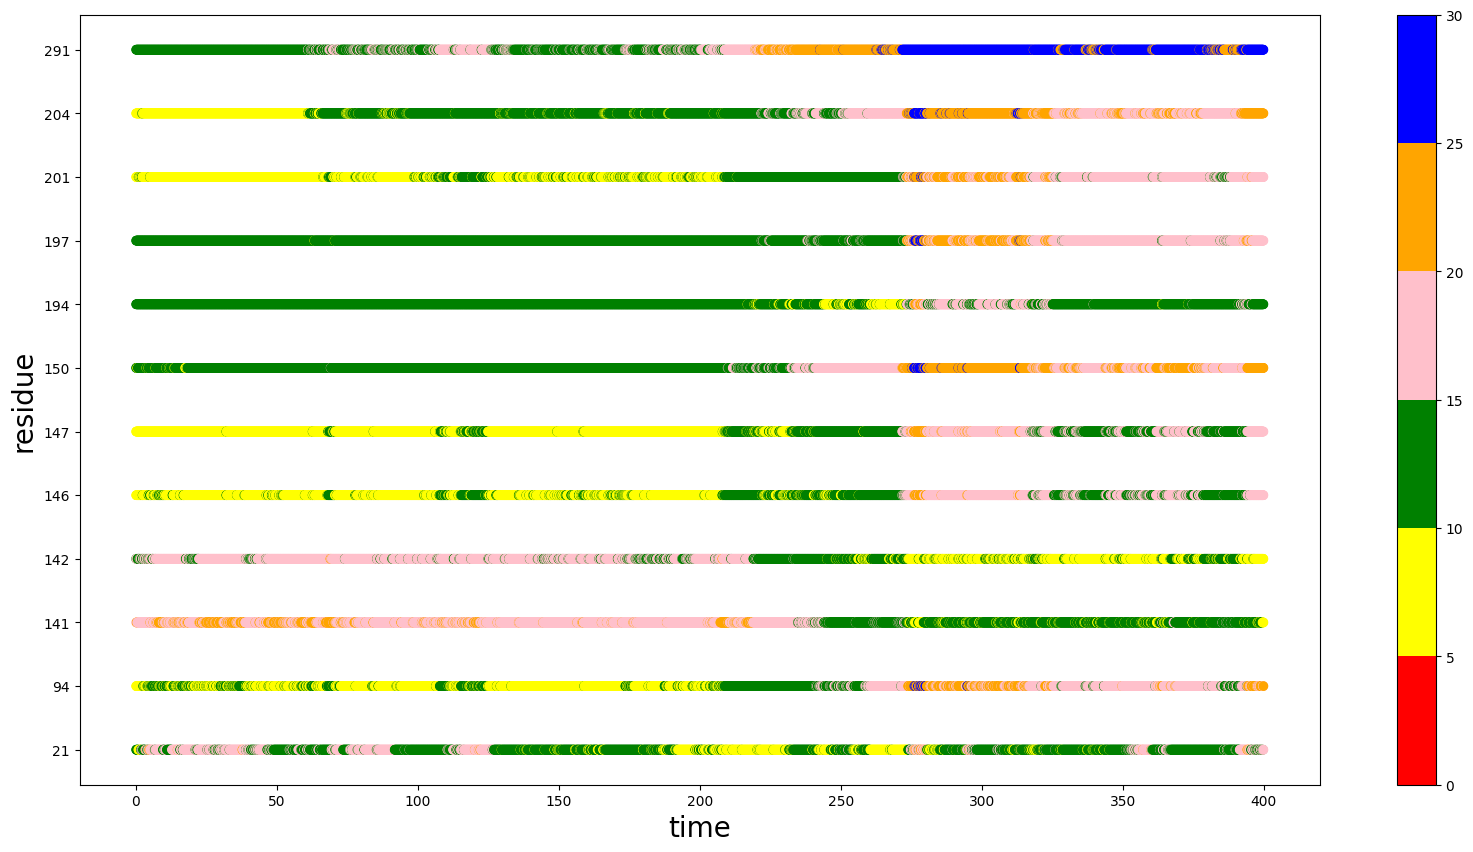

In [2]:
import MDAnalysis as mda
import numpy as np
#import pandas as pd
u=mda.Universe("protein_ligand.gro","final_production.xtc")
from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
import matplotlib.pyplot as plt
final_array=np.zeros((12,4000))
for i in range (0,4000):
    u.trajectory[i]
    selection_1=u.select_atoms("name CA and (resid 42 or resid 115 or resid 162 or resid 163 or resid 167 or resid 168 or resid 171 or resid 215 or resid 218 or resid 222 or resid 225 or resid 312)")
    selection_2=u.select_atoms("resname BMANA or resname BGLCA")
    dist_arr = mda.analysis.distances.distance_array(selection_1.positions,selection_2.center_of_mass(),box=[78.80383,78.80383,78.80383,90.,90.,90.])
    #print ("yes")
    #print (dist_arr.shape)
    for j in range(0,12):
        final_array[j,i]=dist_arr[j,0]
x=[]
y=[]
z=[]
for i in range (1,13):
    for j in range (1,4000):
        y.append(i)
        x.append((j)/10.0)
        z.append(final_array[i-1,j-1])
import matplotlib.pyplot as plt
import matplotlib.colors
fig, axs=plt.subplots(figsize=(20,10))
bounds=[0,5,10,15,20,25,30]
colors=["red","yellow","green","pink","orange","blue"]
cmap = matplotlib.colors.ListedColormap(colors)
norm=matplotlib.colors.BoundaryNorm(bounds,len(colors))
sc = axs.scatter(x, y, c=z, cmap=cmap, norm=norm)
axs.set_yticks([1,2,3,4,5,6,7,8,9,10,11,12])
axs.set_yticklabels(['21','94','141','142','146','147','150','194','197','201','204','291'])
fig.colorbar(sc,spacing="proportional")
plt.xlabel('time',fontsize=20)
plt.ylabel('residue',fontsize=20)
plt.savefig("protein_ligand_contact.jpg")

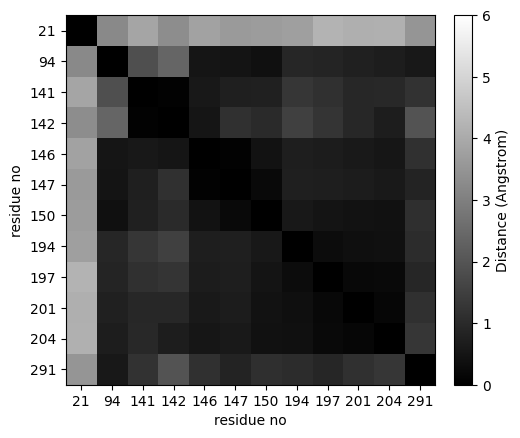

In [4]:
import MDAnalysis as mda
import numpy as np
u=mda.Universe("protein_ligand.gro","final_production.xtc")
from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.animation as animation
from mpl_toolkits.axes_grid1 import make_axes_locatable
fig, ax=plt.subplots()
div = make_axes_locatable(ax)
cax = div.append_axes('right', '5%', '5%')
ax.set_yticks([0,1,2,3,4,5,6,7,8,9,10,11])
ax.set_yticklabels(['21','94','141','142','146','147','150','194','197','201','204','291'])
ax.set_ylabel('residue no')
ax.set_xlabel('residue no')
ax.set_xticks([0,1,2,3,4,5,6,7,8,9,10,11])
ax.set_xticklabels(['21','94','141','142','146','147','150','194','197','201','204','291'])
min_value=0
max_value=6
x=[]
for i in range (0,7501):
    u.trajectory[i]
    selection_1=u.select_atoms("name CA and (resid 42 or resid 115 or resid 162 or resid 163 or resid 167 or resid 168 or resid 171 or resid 215 or resid 218 or resid 222 or resid 225 or resid 312)")
    dist_arr = mda.analysis.distances.distance_array(selection_1.positions,selection_1.positions)
    x.append(dist_arr)
dist_numpy=np.stack(x,axis=2)
std_array=np.std(dist_numpy,axis=2)
im = ax.imshow(std_array, cmap='gray',origin='upper',vmin=min_value,vmax=max_value)
fig.colorbar(im,cax=cax).ax.set_ylabel('Distance (Angstrom)')
#ani = animation.FuncAnimation(fig, animate, frames=len(u.trajectory), interval=70)
plt.savefig("time_fluctuations.jpg")
plt.show()